6+# NETRAVA — Improved EfficientNet-B3 Training Notebook

**Goal:** improve generalization for five-grade diabetic retinopathy classification on APTOS 2019 while preserving a reproducible evaluation protocol.

**What changed:** keep EfficientNet-B3 and the existing dataset workflow; use a short frozen-backbone warm-up followed by low-learning-rate fine-tuning, softer class weights, separate experiment outputs, resumable checkpoints, and automatic restoration of the best validation-QWK checkpoint.

**Important:** this is an experiment, not a promise of a particular accuracy. Run cells from top to bottom. The original `NETRAVA_outputs` folder is not overwritten. This is a research prototype, not a clinically validated diagnostic system.

## Part 1 — Setup

Enable **Runtime → Change runtime type → T4 GPU** in Google Colab. The next cells install/import libraries, check the GPU, set random seeds and connect Google Drive. This version uses a new output folder and does not overwrite the previous run.


In [1]:
# Cell 1 — Import core libraries
import os, sys, json, time, random, hashlib, shutil, zipfile, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix, cohen_kappa_score, roc_auc_score
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)


Python: 3.11.18
PyTorch: 2.15.0+cpu


In [2]:
# Cell 2 — Install model library if needed
try:
    import timm
except ImportError:
    %pip -q install timm
    import timm
print("timm:", timm.__version__)


timm: 1.0.30


In [3]:
# Cell 3 — Check GPU and memory
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("GPU is off. Select Runtime > Change runtime type > GPU.")


Device: cpu
GPU is off. Select Runtime > Change runtime type > GPU.


In [4]:
# Cell 4 — Set seeds and connect Drive
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

from google.colab import drive
drive.mount("/content/drive")

DRIVE_APTOS = Path("/content/drive/MyDrive/APTOS")
OUTPUT_DIR = DRIVE_APTOS / "NETRAVA_B3_improved"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset location:", DRIVE_APTOS)
print("New experiment folder (original results are preserved):", OUTPUT_DIR)


ModuleNotFoundError: No module named 'google'

## Part 2 — Find and validate the dataset

Expected location: `My Drive/APTOS/`. The notebook searches for a complete `train.csv` + `train_images` pair. Do not begin training if image IDs do not match or the files cannot be read.


In [ ]:
# Cell 5 — Check available Colab storage
!df -h /content


Filesystem      Size  Used Avail Use% Mounted on
overlay         113G   43G   71G  38% /


In [ ]:
# Cell 6 — Locate the full dataset
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

def valid_train_csv(path):
    try:
        return {"id_code", "diagnosis"}.issubset(pd.read_csv(path, nrows=0).columns)
    except Exception:
        return False

def match_count(csv_path, image_dir):
    image_ids = {p.stem for p in image_dir.rglob("*")
                 if p.is_file() and p.suffix.lower() in IMAGE_EXTS}
    ids = set(pd.read_csv(csv_path, usecols=["id_code"])["id_code"].astype(str).str.strip())
    return len(ids & image_ids), len(ids)

TRAIN_CSV, TRAIN_IMAGE_DIR = None, None
for root in [DRIVE_APTOS, Path("/content")]:
    if not root.exists():
        continue
    for csv_path in list(root.rglob("train.csv")) + list(root.rglob("train_1.csv")):
        if not valid_train_csv(csv_path):
            continue
        dirs = [csv_path.parent / "train_images"] + list(csv_path.parent.rglob("train_images"))
        for image_dir in dirs:
            if image_dir.is_dir():
                matched, total = match_count(csv_path, image_dir)
                print(f"{csv_path} | {image_dir}: {matched}/{total} matched")
                if matched == total:
                    TRAIN_CSV, TRAIN_IMAGE_DIR = csv_path, image_dir
                    break
        if TRAIN_CSV:
            break
    if TRAIN_CSV:
        break

if TRAIN_CSV is None:
    zips = list(DRIVE_APTOS.glob("*.zip"))
    if not zips:
        raise FileNotFoundError("No complete dataset found. Check My Drive/APTOS.")
    ZIP_PATH = zips[0]
    free_gb = shutil.disk_usage("/content").free / 1e9
    print("ZIP size (GB):", round(ZIP_PATH.stat().st_size / 1e9, 2))
    print("Free Colab disk (GB):", round(free_gb, 2))
    if free_gb < 25:
        raise RuntimeError("Not enough free Colab disk space to safely extract the large ZIP.")
    EXTRACT_DIR = Path("/content/APTOS_extracted")
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    print("Extracting ZIP; this may take a while.")
    with zipfile.ZipFile(ZIP_PATH) as zf:
        bad = zf.testzip()
        if bad:
            raise RuntimeError(f"ZIP integrity check failed: {bad}")
        zf.extractall(EXTRACT_DIR)
    for csv_path in EXTRACT_DIR.rglob("train.csv"):
        if valid_train_csv(csv_path):
            for image_dir in [csv_path.parent / "train_images"] + list(csv_path.parent.rglob("train_images")):
                if image_dir.is_dir() and match_count(csv_path, image_dir)[0] == match_count(csv_path, image_dir)[1]:
                    TRAIN_CSV, TRAIN_IMAGE_DIR = csv_path, image_dir
                    break
        if TRAIN_CSV:
            break

if TRAIN_CSV is None or TRAIN_IMAGE_DIR is None:
    raise FileNotFoundError("Could not find complete train.csv + train_images.")
print("CSV:", TRAIN_CSV)
print("Image folder:", TRAIN_IMAGE_DIR)


ZIP size (GB): 10.22
Free Colab disk (GB): 75.19
Extracting ZIP; this may take a while.
CSV: /content/APTOS_extracted/train.csv
Image folder: /content/APTOS_extracted/train_images


In [ ]:
# Cell 7 — Load labels and verify image paths
df = pd.read_csv(TRAIN_CSV)
df["id_code"] = df["id_code"].astype(str).str.strip()
df["diagnosis"] = pd.to_numeric(df["diagnosis"], errors="raise").astype(int)

assert {"id_code", "diagnosis"}.issubset(df.columns), "CSV must contain id_code and diagnosis."
assert df["id_code"].notna().all() and df["id_code"].ne("").all(), "Blank image IDs found."
assert not df["id_code"].duplicated().any(), "Duplicate id_code values found. Investigate before training."
assert df["diagnosis"].between(0, 4).all(), "Labels must be integers from 0 to 4."

image_map = {
    p.stem: p for p in TRAIN_IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
}
df["image_path"] = df["id_code"].map(lambda image_id: str(image_map[image_id]) if image_id in image_map else None)

print("CSV records:", len(df))
print("Matched images:", df["image_path"].notna().sum())
print("Missing images:", df["image_path"].isna().sum())
if df["image_path"].isna().any():
    display(df.loc[df["image_path"].isna(), ["id_code", "diagnosis"]].head())
    raise FileNotFoundError("Some image IDs did not match. Fix the data paths before training.")

display(df.head())


CSV records: 3662
Matched images: 3662
Missing images: 0


,id_code,diagnosis,image_path
0,000c1434d8d7,2,/content/APTOS_extracted/train_images/000c1434...
1,001639a390f0,4,/content/APTOS_extracted/train_images/001639a3...
2,0024cdab0c1e,1,/content/APTOS_extracted/train_images/0024cdab...
3,002c21358ce6,0,/content/APTOS_extracted/train_images/002c2135...
4,005b95c28852,0,/content/APTOS_extracted/train_images/005b95c2...


In [ ]:
# Cell 8 — Check labels and missing values
print("Column types:")
display(df[["id_code", "diagnosis"]].dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df[["id_code", "diagnosis", "image_path"]].isna().sum().to_frame("missing"))
print("\nDuplicate IDs:", df["id_code"].duplicated().sum())
print("Unique image IDs:", df["id_code"].nunique())
print("Grade range:", df["diagnosis"].min(), "to", df["diagnosis"].max())


Column types:


,dtype
id_code,object
diagnosis,int64



Missing values:


,missing
id_code,0
diagnosis,0
image_path,0



Duplicate IDs: 0
Unique image IDs: 3662
Grade range: 0 to 4


In [ ]:
# Cell 9 — Verify that image files can be opened
bad_images = []
for i, row in enumerate(df.itertuples(), start=1):
    try:
        with Image.open(row.image_path) as im:
            im.verify()
    except Exception as exc:
        bad_images.append((row.id_code, str(exc)))
    if i % 500 == 0:
        print(f"Checked {i}/{len(df)} images")

print("Unreadable images:", len(bad_images))
if bad_images:
    display(pd.DataFrame(bad_images, columns=["id_code", "error"]).head(20))
    raise RuntimeError("Unreadable images found. Investigate them before training.")


Checked 500/3662 images
Checked 1000/3662 images
Checked 1500/3662 images
Checked 2000/3662 images
Checked 2500/3662 images
Checked 3000/3662 images
Checked 3500/3662 images
Unreadable images: 0


## Part 3 — Exploratory Data Analysis (EDA)

EDA describes label imbalance and image variation before training. Brightness and size outliers are flagged for review, not automatically removed.


In [ ]:
# Cell 10 — Grade counts and percentages
grade_counts = df["diagnosis"].value_counts().reindex(range(5), fill_value=0)
grade_summary = pd.DataFrame({
    "grade": range(5),
    "meaning": ["No DR", "Mild", "Moderate", "Severe", "Proliferative DR"],
    "count": grade_counts.values,
    "percent": (grade_counts.values / len(df) * 100).round(2)
})
display(grade_summary)


,grade,meaning,count,percent
0,0,No DR,1805,49.29
1,1,Mild,370,10.10
2,2,Moderate,999,27.28
3,3,Severe,193,5.27
4,4,Proliferative DR,295,8.06


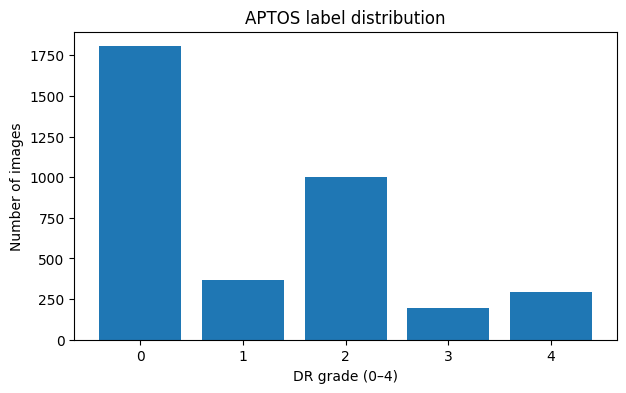

In [ ]:
# Cell 11 — Plot class imbalance
plt.figure(figsize=(7, 4))
plt.bar(grade_counts.index.astype(str), grade_counts.values)
plt.xlabel("DR grade (0–4)")
plt.ylabel("Number of images")
plt.title("APTOS label distribution")
plt.show()


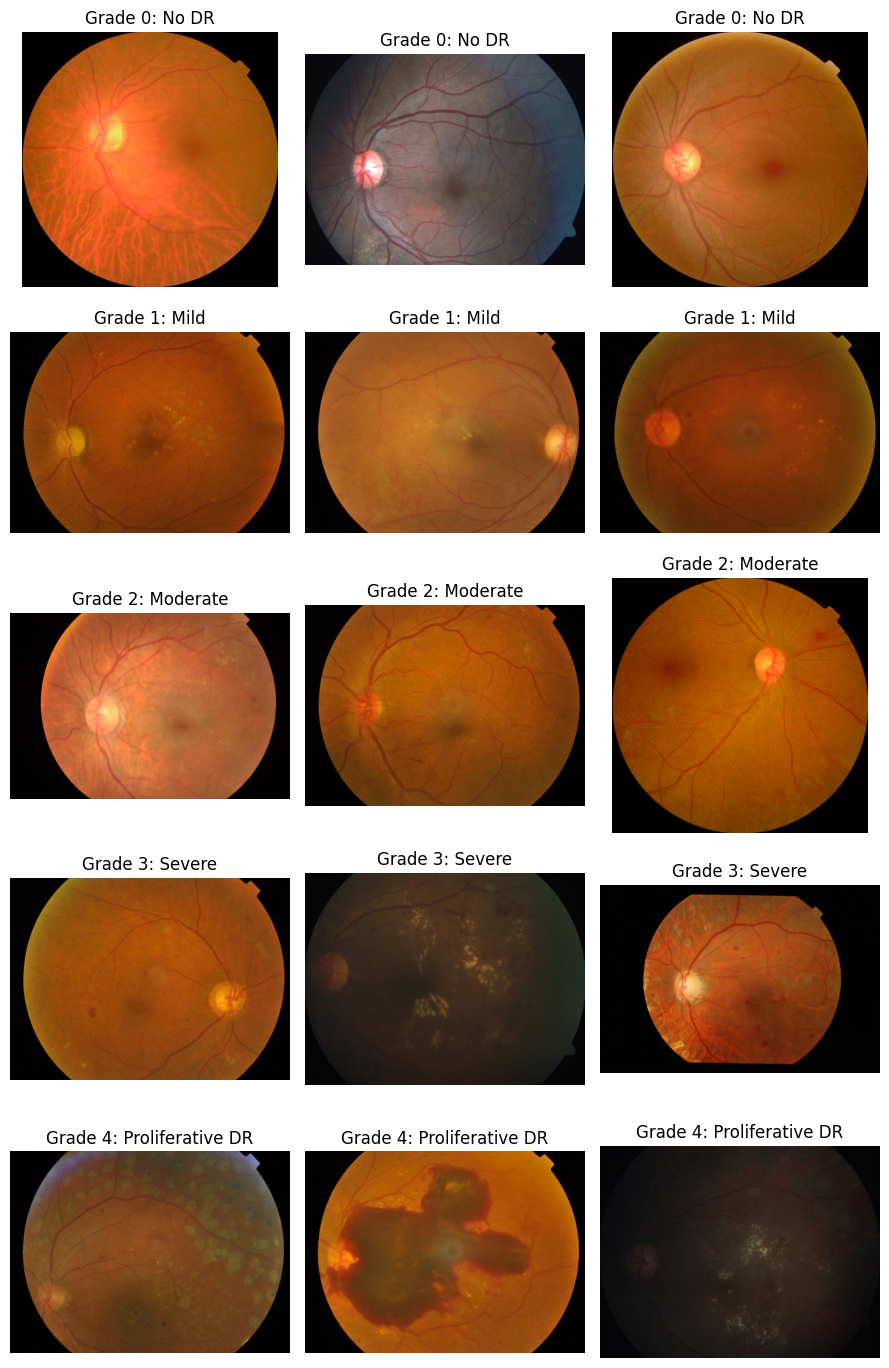

In [ ]:
# Cell 12 — Display sample images from every grade
fig, axes = plt.subplots(5, 3, figsize=(9, 14))
for grade in range(5):
    examples = df[df["diagnosis"] == grade].sample(
        min(3, (df["diagnosis"] == grade).sum()), random_state=SEED
    )
    for col in range(3):
        ax = axes[grade, col]
        ax.axis("off")
        if col < len(examples):
            row = examples.iloc[col]
            with Image.open(row["image_path"]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"Grade {grade}: {CLASS_NAMES[grade] if 'CLASS_NAMES' in globals() else ['No DR','Mild','Moderate','Severe','Proliferative DR'][grade]}")
plt.tight_layout()
plt.show()


In [ ]:
# Cell 13 — Image dimensions and file sizes
records = []
for row in df.itertuples():
    with Image.open(row.image_path) as im:
        records.append({
            "id_code": row.id_code,
            "diagnosis": row.diagnosis,
            "width": im.width,
            "height": im.height,
            "mode": im.mode,
            "file_kb": Path(row.image_path).stat().st_size / 1024
        })
image_stats = pd.DataFrame(records)
display(image_stats[["width", "height", "file_kb"]].describe().round(2))
print("Image modes:")
display(image_stats["mode"].value_counts().to_frame("count"))


,width,height,file_kb
count,3662.00,3662.00,3662.00
mean,2015.18,1526.83,2294.22
std,884.30,542.66,1721.14
min,474.00,358.00,216.54
25%,1050.00,1050.00,980.46
50%,2144.00,1536.00,1889.60
75%,2588.00,1958.00,2780.13
max,4288.00,2848.00,7494.43


Image modes:


,count
mode,
RGB,3662


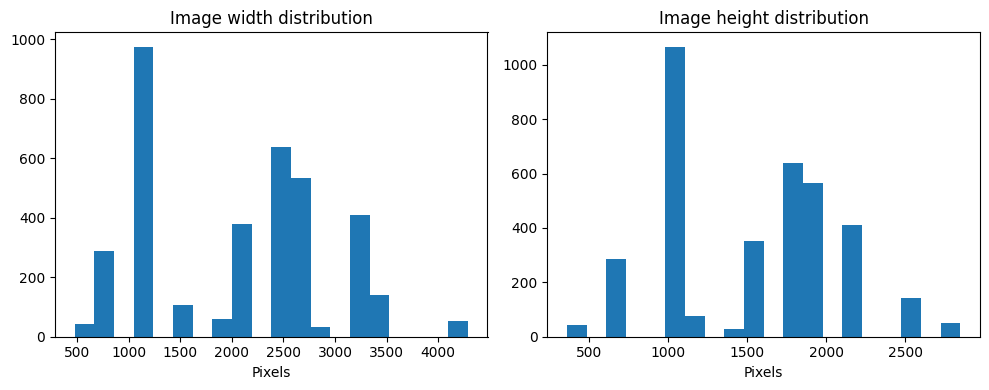

In [ ]:
# Cell 14 — Plot image-size distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(image_stats["width"], bins=20)
axes[0].set_title("Image width distribution")
axes[0].set_xlabel("Pixels")
axes[1].hist(image_stats["height"], bins=20)
axes[1].set_title("Image height distribution")
axes[1].set_xlabel("Pixels")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
diagnosis,,,,,,,,
0,1805.0,0.255,0.077,0.059,0.184,0.280,0.321,0.476
1,370.0,0.272,0.056,0.114,0.236,0.269,0.310,0.471
2,999.0,0.272,0.063,0.099,0.230,0.270,0.316,0.508
3,193.0,0.257,0.067,0.131,0.203,0.252,0.309,0.460
4,295.0,0.262,0.062,0.107,0.225,0.261,0.301,0.482


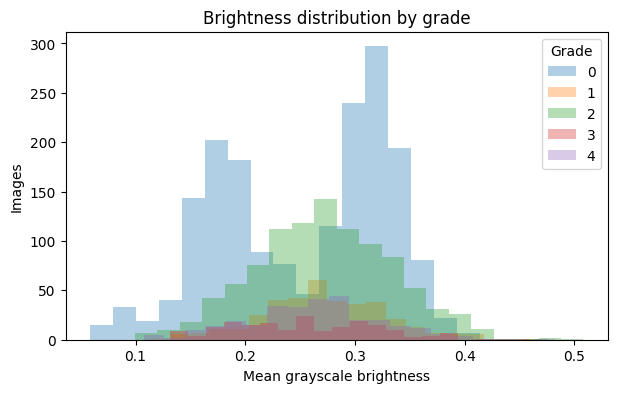

In [ ]:
# Cell 15 — Basic image brightness audit
brightness = []
for path in df["image_path"]:
    with Image.open(path) as im:
        gray = np.asarray(im.convert("L").resize((128, 128)), dtype=np.float32) / 255.0
        brightness.append(float(gray.mean()))
image_stats["mean_brightness"] = brightness
display(image_stats.groupby("diagnosis")["mean_brightness"].describe().round(3))
plt.figure(figsize=(7, 4))
for grade in range(5):
    vals = image_stats.loc[image_stats["diagnosis"] == grade, "mean_brightness"]
    plt.hist(vals, bins=20, alpha=0.35, label=str(grade))
plt.xlabel("Mean grayscale brightness")
plt.ylabel("Images")
plt.title("Brightness distribution by grade")
plt.legend(title="Grade")
plt.show()


In [ ]:
# Cell 16 — Show possible dark/bright outliers for review
low_cut, high_cut = image_stats["mean_brightness"].quantile([0.01, 0.99])
outliers = image_stats[(image_stats["mean_brightness"] < low_cut) |
                       (image_stats["mean_brightness"] > high_cut)]
print("Brightness outliers to inspect (not automatic exclusions):", len(outliers))
display(outliers.sort_values("mean_brightness").head(10))


Brightness outliers to inspect (not automatic exclusions): 74


,id_code,diagnosis,width,height,mode,file_kb,mean_brightness
3056,d4583e9525dc,0,2048,1536,RGB,1788.821289,0.058742
1932,87d46b1cc4e9,0,2048,1536,RGB,1766.291016,0.065052
2950,ccd6dcb2f568,0,2048,1536,RGB,1782.851562,0.065288
934,436fa3fd145a,0,2048,1536,RGB,1816.233398,0.067298
1622,7269a1d84a57,0,2048,1536,RGB,1758.260742,0.067389
1460,66460ecab347,0,2048,1536,RGB,1719.168945,0.069457
1542,6cb96a6fb029,0,2048,1536,RGB,1789.491211,0.070010
3124,d91635f380b4,0,2048,1536,RGB,1705.250000,0.070251
1618,7214fc7cbe03,0,2048,1536,RGB,1754.464844,0.072719
1277,58eb3809f456,0,2048,1536,RGB,1734.302734,0.073783


## Part 4 — Duplicate audit and data splitting

Exact duplicate files are detected by SHA-256. Conflicting-label duplicate groups are excluded and repeated identical images are reduced to one. The data is split into 70% train, 15% validation and 15% test.

**Limitation:** this is an image-level split. If reliable patient identifiers are available, patient-level splitting is preferable. Exact-hash checks do not detect every near-duplicate or multiple images from one patient.


In [ ]:
# Cell 17 — Calculate SHA-256 hashes
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

hashes = []
for i, path in enumerate(df["image_path"], 1):
    hashes.append(sha256_file(path))
    if i % 500 == 0:
        print(f"Hashed {i}/{len(df)}")
df["sha256"] = hashes


Hashed 500/3662
Hashed 1000/3662
Hashed 1500/3662
Hashed 2000/3662
Hashed 2500/3662
Hashed 3000/3662
Hashed 3500/3662


In [ ]:
# Cell 18 — Remove exact duplicate conflicts
hash_label_counts = df.groupby("sha256")["diagnosis"].nunique()
conflict_hashes = set(hash_label_counts[hash_label_counts > 1].index)
conflict_rows = int(df["sha256"].isin(conflict_hashes).sum())
repeated_rows = int(df.duplicated("sha256", keep="first").sum())

clean_df = df[~df["sha256"].isin(conflict_hashes)].copy()
clean_df = clean_df.drop_duplicates("sha256", keep="first").reset_index(drop=True)

print("Starting rows:", len(df))
print("Rows in conflicting-label duplicate groups:", conflict_rows)
print("Repeated exact-image rows:", repeated_rows)
print("Rows retained:", len(clean_df))
display(clean_df["diagnosis"].value_counts().sort_index().to_frame("count"))


Starting rows: 3662
Rows in conflicting-label duplicate groups: 62
Repeated exact-image rows: 128
Rows retained: 3504


,count
diagnosis,
0,1796
1,338
2,922
3,177
4,271


In [ ]:
# Cell 19 — Create reproducible train, validation and test splits
train_df, remainder = train_test_split(
    clean_df, test_size=0.30, random_state=SEED, stratify=clean_df["diagnosis"]
)
val_df, test_df = train_test_split(
    remainder, test_size=0.50, random_state=SEED, stratify=remainder["diagnosis"]
)

for split_name, split_df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    split_df.to_csv(OUTPUT_DIR / f"{split_name}_split.csv", index=False)
    grade_counts = split_df["diagnosis"].value_counts().reindex(range(5), fill_value=0)
    print(f"{split_name}: {len(split_df)} images | grade counts: {grade_counts.to_dict()}")
    assert (grade_counts > 0).all(), f"A grade is missing from {split_name}."


train: 2452 images | grade counts: {0: 1257, 1: 236, 2: 645, 3: 124, 4: 190}
validation: 526 images | grade counts: {0: 269, 1: 51, 2: 139, 3: 26, 4: 41}
test: 526 images | grade counts: {0: 270, 1: 51, 2: 138, 3: 27, 4: 40}


## Part 5 — Preprocessing and batches

Images are resized to 300×300 without stretching and normalized with ImageNet statistics. Only training images receive moderate augmentation. Keep this preprocessing fixed for the first redesigned run so that the main comparison tests the training strategy rather than several simultaneous changes.

In [ ]:
# Cell 20 — Improved experiment settings (retain EfficientNet-B3)
CLASS_NAMES = {
    0: "No DR", 1: "Mild", 2: "Moderate",
    3: "Severe", 4: "Proliferative DR"
}

MODEL_NAME = "efficientnet_b3"
IMG_SIZE = 300
BATCH_SIZE = 8 if DEVICE.type == "cuda" else 2
MAX_EPOCHS = 45
WARMUP_EPOCHS = 3       # train classifier first; then unfreeze the backbone
PATIENCE = 9
MIN_QWK_IMPROVEMENT = 0.001
NUM_WORKERS = 2

print(f"Model: {MODEL_NAME} | input: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch size: {BATCH_SIZE} | maximum epochs: {MAX_EPOCHS}")
print(f"Frozen-head warm-up: {WARMUP_EPOCHS} epochs")
print(f"Early stopping patience: {PATIENCE}")
print("This experiment tests a more controlled fine-tuning strategy; results are not guaranteed.")

Model: efficientnet_b3 | input: 300x300
Batch size: 8 | maximum epochs: 45
Frozen-head warm-up: 3 epochs
Early stopping patience: 9
This experiment tests a more controlled fine-tuning strategy; results are not guaranteed.


In [ ]:
# Cell 20 — Define image transforms (aspect ratio preserved with padding)
# Retinal images can have different dimensions. Padding avoids stretching the fundus.
from PIL import ImageOps

class ResizeWithPadding:
    def __init__(self, size=IMG_SIZE, fill=(0, 0, 0)):
        self.size = size
        self.fill = fill

    def __call__(self, image):
        image = image.convert("RGB")
        image.thumbnail((self.size, self.size), Image.Resampling.LANCZOS)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - image.width) // 2
        top = (self.size - image.height) // 2
        canvas.paste(image, (left, top))
        return canvas

resize_with_padding = ResizeWithPadding(IMG_SIZE)

imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    resize_with_padding,
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8, fill=(0, 0, 0)),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
eval_transform = transforms.Compose([
    resize_with_padding,
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
print("Aspect-ratio-preserving resize enabled:", IMG_SIZE, "x", IMG_SIZE)


Aspect-ratio-preserving resize enabled: 300 x 300


In [ ]:
# Cell 21 — Define APTOS Dataset
class APTOSDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["image_path"]) as image:
            image = self.transform(image.convert("RGB"))
        return image, int(row["diagnosis"])


In [ ]:
# Cell 22 — Create DataLoaders and check a batch
train_ds = APTOSDataset(train_df, train_transform)
val_ds = APTOSDataset(val_df, eval_transform)
test_ds = APTOSDataset(test_df, eval_transform)

loader_args = dict(
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=NUM_WORKERS > 0
)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

xb, yb = next(iter(train_loader))
print("Image batch:", xb.shape)
print("Label batch:", yb.shape)
print("Number of batches — train:", len(train_loader),
      "| validation:", len(val_loader), "| test:", len(test_loader))


Image batch: torch.Size([8, 3, 300, 300])
Label batch: torch.Size([8])
Number of batches — train: 307 | validation: 66 | test: 66


## Part 6 — Model and staged training

We retain pretrained EfficientNet-B3 so this run directly addresses the training strategy rather than changing the backbone again. For the first three epochs, only the five-grade classifier is trainable. The backbone is then unfrozen and fine-tuned with a smaller learning rate. Softer square-root class weights are used to reduce the risk of overemphasizing rare grades. The best checkpoint is selected by validation QWK, then restored before test evaluation.

In [ ]:
# Cell 23 — Load pretrained EfficientNet-B3
model = timm.create_model(
    MODEL_NAME, pretrained=True, num_classes=5, drop_rate=0.30
).to(DEVICE)
print("Model ready on:", DEVICE)
print("Classifier:", model.get_classifier())

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model ready on: cuda
Classifier: Linear(in_features=1536, out_features=5, bias=True)


In [ ]:
# Cell 24 — Softer class weighting, discriminative learning rates, AMP
counts = train_df["diagnosis"].value_counts().reindex(range(5), fill_value=0).to_numpy()
assert np.all(counts > 0), "Every grade must appear in training."

# Square-root inverse-frequency weighting is less aggressive than 1/count.
weights = np.sqrt(counts.sum() / (5.0 * counts))
weights = weights / weights.mean()
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.02)

head_params = list(model.get_classifier().parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-4},
    ],
    weight_decay=1e-4,
)
# Scheduler is stepped only during the fine-tuning stage.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=max(1, MAX_EPOCHS - WARMUP_EPOCHS), eta_min=1e-6
)
USE_AMP = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
WARMUP_ACTIVE = False

print("Class counts:", counts.tolist())
print("Softer class weights:", class_weights.cpu().numpy().round(3))
print("Mixed precision:", USE_AMP)

Class counts: [1257, 236, 645, 124, 190]
Softer class weights: [0.478 1.103 0.667 1.522 1.23 ]
Mixed precision: True


In [ ]:
# Cell 25 — Run one epoch with live progress
from tqdm.auto import tqdm

def run_epoch(loader, training):
    model.train(training)
    # During classifier-only warm-up, keep BatchNorm running statistics fixed.
    if training and WARMUP_ACTIVE:
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                module.eval()

    loss_sum, seen = 0.0, 0
    true_labels, predicted_labels = [], []
    phase = "TRAIN" if training else "VALIDATION"
    progress = tqdm(loader, desc=phase, total=len(loader), dynamic_ncols=True)
    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch_idx, (images, labels) in enumerate(progress, start=1):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], 1.0
                )
                scaler.step(optimizer)
                scaler.update()

            n = labels.size(0)
            loss_sum += loss.item() * n
            seen += n
            predictions = logits.argmax(dim=1)
            true_labels.extend(labels.detach().cpu().tolist())
            predicted_labels.extend(predictions.detach().cpu().tolist())
            progress.set_postfix(
                batch=f"{batch_idx}/{len(loader)}",
                loss=f"{loss.item():.4f}", avg_loss=f"{loss_sum / seen:.4f}"
            )

    return {
        "loss": loss_sum / max(seen, 1),
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "balanced_accuracy": balanced_accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(true_labels, predicted_labels, labels=range(5), average="macro", zero_division=0),
        **{f"recall_grade_{grade}": float(value) for grade, value in enumerate(
            recall_score(true_labels, predicted_labels, labels=range(5), average=None, zero_division=0)
        )},
        "qwk": cohen_kappa_score(true_labels, predicted_labels, labels=range(5), weights="quadratic"),
    }

In [ ]:
%pip install -q tqdm

In [ ]:
required = [
    "OUTPUT_DIR", "MODEL_NAME", "DEVICE", "model",
    "optimizer", "scheduler", "scaler", "train_loader",
    "val_loader", "MAX_EPOCHS", "PATIENCE",
    "MIN_QWK_IMPROVEMENT", "USE_AMP", "criterion",
    "run_epoch", "SEED", "CLASS_NAMES"
]

for name in required:
    print(f"{name}: {'OK' if name in globals() else 'MISSING'}")

OUTPUT_DIR: OK
MODEL_NAME: OK
DEVICE: OK
model: OK
optimizer: OK
scheduler: OK
scaler: OK
train_loader: OK
val_loader: OK
MAX_EPOCHS: OK
PATIENCE: OK
MIN_QWK_IMPROVEMENT: OK
USE_AMP: OK
criterion: OK
run_epoch: OK
SEED: OK
CLASS_NAMES: OK


In [ ]:

# Cell 26 — Train NETRAVA with checkpoint saving and resume support

from tqdm.auto import tqdm
import time
import torch
import pandas as pd
from torch.utils.data import DataLoader

# 1. Data loaders
NUM_WORKERS = 0
BATCH_SIZE = 8 if DEVICE.type == "cuda" else 2

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

# 2. Save paths
BEST_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}_staged.pth"
RESUME_PATH = OUTPUT_DIR / f"resume_{MODEL_NAME}_staged.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history_staged.csv"

# 3. Initialize training state
best_qwk = -1.0
best_epoch = 0
stale_epochs = 0
history = []
start_epoch = 1

# 4. Resume if a compatible checkpoint exists
RESUME_TRAINING = RESUME_PATH.exists()

if RESUME_TRAINING:
    state = torch.load(
        RESUME_PATH, map_location=DEVICE, weights_only=False
    )

    if (
        state.get("model_name") != MODEL_NAME
        or state.get("img_size") != IMG_SIZE
    ):
        raise RuntimeError(
            "Checkpoint model/image size mismatch. "
            "Use a compatible checkpoint."
        )

    model.load_state_dict(state["model_state_dict"])
    optimizer.load_state_dict(state["optimizer_state_dict"])
    scheduler.load_state_dict(state["scheduler_state_dict"])

    scaler_state = state.get("scaler_state_dict", {})
    if scaler.is_enabled() and scaler_state:
        scaler.load_state_dict(scaler_state)

    best_qwk = state.get("best_qwk", -1.0)
    best_epoch = state.get("best_epoch", 0)
    stale_epochs = state.get("stale_epochs", 0)
    history = state.get("history", [])
    start_epoch = state["epoch"] + 1

    print(f"Resuming from epoch {start_epoch}")
    print(f"Best QWK so far: {best_qwk:.4f}")
else:
    print("Starting a fresh training run.")

# 5. Training loop
for epoch in range(start_epoch, MAX_EPOCHS + 1):
    started = time.time()
    warmup_active = epoch <= WARMUP_EPOCHS

    # Keep the classifier trainable during warm-up.
    for parameter in model.parameters():
        parameter.requires_grad = not warmup_active

    if warmup_active:
        for parameter in model.get_classifier().parameters():
            parameter.requires_grad = True

    stage = "HEAD WARM-UP" if warmup_active else "FULL FINE-TUNING"
    print(f"\n===== EPOCH {epoch}/{MAX_EPOCHS} | {stage} =====")

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    if not warmup_active:
        scheduler.step()

    row = {"epoch": epoch, "stage": stage}
    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    elapsed = time.time() - started
    print(
        f"Epoch {epoch}/{MAX_EPOCHS} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"QWK: {val_metrics['qwk']:.4f} | "
        f"Time: {elapsed / 60:.1f} min",
        flush=True
    )

    # 6. Save the best model based on validation QWK
    if val_metrics["qwk"] > best_qwk + MIN_QWK_IMPROVEMENT:
        best_qwk = float(val_metrics["qwk"])
        best_epoch = epoch
        stale_epochs = 0

        torch.save({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "img_size": IMG_SIZE,
            "model_state_dict": model.state_dict(),
            "best_val_qwk": best_qwk,
            "seed": SEED,
            "class_names": CLASS_NAMES,
        }, BEST_PATH)

        print("Best model checkpoint saved.")
    else:
        stale_epochs += 1

    # 7. Save resumable training state after every epoch
    torch.save({
        "epoch": epoch,
        "model_name": MODEL_NAME,
        "img_size": IMG_SIZE,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_qwk": best_qwk,
        "best_epoch": best_epoch,
        "stale_epochs": stale_epochs,
        "history": history,
    }, RESUME_PATH)

    if stale_epochs >= PATIENCE:
        print("Early stopping: validation QWK did not improve.")
        break

# 8. Load the best checkpoint for downstream evaluation
if not BEST_PATH.exists():
    raise RuntimeError("No best checkpoint was created.")

best_checkpoint = torch.load(
    BEST_PATH, map_location=DEVICE, weights_only=False
)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("\nTraining finished.")
print("Best epoch:", best_checkpoint["epoch"])
print("Best validation QWK:", round(best_checkpoint["best_val_qwk"], 4))
print("Best model:", BEST_PATH)
print("Resume checkpoint:", RESUME_PATH)
print("Training history:", HISTORY_PATH)


Resuming from epoch 5
Best QWK so far: 0.7077

===== EPOCH 5/45 | FULL FINE-TUNING =====


TRAIN:   0%|          | 0/307 [00:00<?, ?it/s]

VALIDATION:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 5/45 | Train loss: 1.4374 | Val loss: 1.2541 | Val accuracy: 0.6806 | Macro-F1: 0.4594 | QWK: 0.7159 | Time: 7.2 min
Best model checkpoint saved.

===== EPOCH 6/45 | FULL FINE-TUNING =====


TRAIN:   0%|          | 0/307 [00:00<?, ?it/s]

VALIDATION:   0%|          | 0/66 [00:00<?, ?it/s]

... (66 outputs left out)

Epoch 28/45 | Train loss: 0.4664 | Val loss: 0.9423 | Val accuracy: 0.8099 | Macro-F1: 0.6185 | QWK: 0.8663 | Time: 7.0 min

===== EPOCH 29/45 | FULL FINE-TUNING =====


TRAIN:   0%|          | 0/307 [00:00<?, ?it/s]

VALIDATION:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 29/45 | Train loss: 0.4438 | Val loss: 0.8989 | Val accuracy: 0.8061 | Macro-F1: 0.6288 | QWK: 0.8677 | Time: 7.0 min
Early stopping: validation QWK did not improve.

Training finished.
Best epoch: 20
Best validation QWK: 0.8716
Best model: /content/drive/MyDrive/APTOS/NETRAVA_B3_improved/best_efficientnet_b3_staged.pth
Resume checkpoint: /content/drive/MyDrive/APTOS/NETRAVA_B3_improved/resume_efficientnet_b3_staged.pth
Training history: /content/drive/MyDrive/APTOS/NETRAVA_B3_improved/training_history_staged.csv


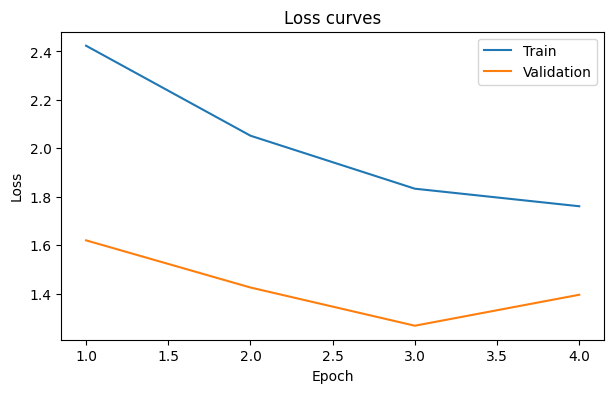

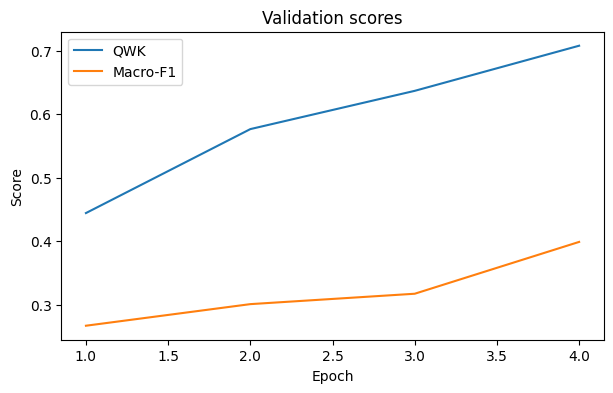

In [ ]:
# Cell 27 — Plot loss and validation metrics
history_df = pd.read_csv(HISTORY_PATH)
plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss curves"); plt.legend(); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["val_qwk"], label="QWK")
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="Macro-F1")
plt.xlabel("Epoch"); plt.ylabel("Score"); plt.title("Validation scores"); plt.legend(); plt.show()


## Part 7 — Locked test evaluation

The test split must not be used to tune the architecture, hyperparameters or referral threshold. Use these results once the model-selection decisions are finished.


In [ ]:
# Cell 28 — Load the best checkpoint before test evaluation
BEST_PATH = OUTPUT_DIR / f"best_{MODEL_NAME}_staged.pth"
checkpoint = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)
assert checkpoint["model_name"] == MODEL_NAME
assert checkpoint["img_size"] == IMG_SIZE
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Loaded best checkpoint from epoch:", checkpoint["epoch"])
print("Best validation QWK:", round(float(checkpoint["best_val_qwk"]), 4))

Loaded best checkpoint from epoch: 4
Best validation QWK: 0.7077


In [ ]:
# Cell 29 — Compute test metrics
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(images)
        probs = torch.softmax(logits.float(), dim=1)
        y_true.extend(labels.tolist())
        y_pred.extend(probs.argmax(1).cpu().tolist())
        y_prob.extend(probs.cpu().numpy())

test_metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "qwk": cohen_kappa_score(y_true, y_pred, labels=range(5), weights="quadratic")
}
print({k: round(float(v), 4) for k, v in test_metrics.items()})
print(classification_report(
    y_true, y_pred, labels=range(5),
    target_names=[CLASS_NAMES[i] for i in range(5)], zero_division=0
))


In [ ]:
# Cell 30 — Bootstrap confidence intervals for test accuracy and macro-F1
# These intervals describe sampling uncertainty on this test set; they do not replace external validation.
rng = np.random.default_rng(SEED)
true_arr = np.asarray(y_true)
pred_arr = np.asarray(y_pred)
n_bootstrap = 1000
boot_accuracy, boot_macro_f1 = [], []

for _ in range(n_bootstrap):
    indices = rng.integers(0, len(true_arr), len(true_arr))
    boot_accuracy.append(accuracy_score(true_arr[indices], pred_arr[indices]))
    boot_macro_f1.append(f1_score(
        true_arr[indices], pred_arr[indices],
        labels=range(5), average="macro", zero_division=0
    ))

for metric_name, values in [
    ("Accuracy", boot_accuracy), ("Macro-F1", boot_macro_f1)
]:
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"{metric_name}: 95% bootstrap CI [{low:.4f}, {high:.4f}]")


In [ ]:
# Cell 31 — Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(5))
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Held-out test confusion matrix")
plt.xlabel("Predicted grade"); plt.ylabel("True grade")
plt.xticks(range(5), range(5)); plt.yticks(range(5), range(5))
for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar(); plt.show()


In [ ]:
# Cell 32 — Referable-DR sensitivity and specificity
# Example threshold: grades 2–4 are referable. Confirm this threshold for the intended protocol.
true_ref = np.array(y_true) >= 2
pred_ref = np.array(y_pred) >= 2
tn, fp, fn, tp = confusion_matrix(true_ref, pred_ref, labels=[False, True]).ravel()
sensitivity = tp / (tp + fn) if tp + fn else float("nan")
specificity = tn / (tn + fp) if tn + fp else float("nan")
print(f"TP={tp}, FN={fn}, TN={tn}, FP={fp}")
print("Sensitivity:", round(sensitivity, 4))
print("Specificity:", round(specificity, 4))


## Part 8 — Grad-CAM explainability

Grad-CAM highlights image regions influencing the selected class score. It is an interpretation aid—not proof that the model found a lesion or that its prediction is correct.


In [ ]:
# Cell 33 — Generate a Grad-CAM heatmap for one image
import torch.nn.functional as F

def gradcam_image(image_path):
    model.eval()
    captured = {}

    def save_activation(module, inputs, output):
        captured["activation"] = output

    def save_gradient(module, grad_input, grad_output):
        captured["gradient"] = grad_output[0]

    target_layer = model.conv_head
    forward_handle = target_layer.register_forward_hook(save_activation)
    backward_handle = target_layer.register_full_backward_hook(save_gradient)

    try:
        with Image.open(image_path) as im:
            original = im.convert("RGB")
            display_image = resize_with_padding(original)
            input_tensor = eval_transform(original).unsqueeze(0).to(DEVICE)

        model.zero_grad(set_to_none=True)
        logits = model(input_tensor)
        predicted_grade = int(logits.argmax(1).item())
        logits[0, predicted_grade].backward()

        activations = captured["activation"].detach()
        gradients = captured["gradient"].detach()
        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(
            cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
        )
        cam = cam[0, 0].cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(display_image)
        plt.title("Preprocessed input image")
        plt.axis("off")
        plt.subplot(1, 2, 2)
        plt.imshow(display_image)
        plt.imshow(cam, cmap="jet", alpha=0.4)
        plt.title(f"Grad-CAM — predicted grade {predicted_grade}")
        plt.axis("off")
        plt.tight_layout()
        plt.show()
        print("Predicted grade:", predicted_grade, CLASS_NAMES[predicted_grade])
        print("Caution: heatmap is an interpretation aid, not proof of clinical correctness.")
    finally:
        forward_handle.remove()
        backward_handle.remove()

gradcam_image(test_df.iloc[0]["image_path"])


In [ ]:
# Cell 34 — One prediction with class scores
def predict_image(image_path):
    with Image.open(image_path) as im:
        tensor = eval_transform(im.convert("RGB")).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        with torch.amp.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(tensor)
        scores = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()
    grade = int(scores.argmax())
    return {
        "grade": grade,
        "label": CLASS_NAMES[grade],
        "class_scores": {CLASS_NAMES[i]: round(float(scores[i]), 4) for i in range(5)},
        "notice": "Research output only; not a medical diagnosis."
    }

print(predict_image(test_df.iloc[0]["image_path"]))


In [ ]:
# Cell 35 — Save predictions and evaluation report
predictions = pd.DataFrame({
    "image_path": test_df["image_path"].reset_index(drop=True),
    "true_grade": y_true,
    "predicted_grade": y_pred,
})
for grade in range(5):
    predictions[f"score_grade_{grade}"] = np.asarray(y_prob)[:, grade]
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

summary = {
    "model": MODEL_NAME,
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_qwk": float(checkpoint["best_val_qwk"]),
    "validation_accuracy_at_best_epoch": float(checkpoint.get("val_accuracy", float("nan"))),
    "validation_macro_f1_at_best_epoch": float(checkpoint.get("val_macro_f1", float("nan"))),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "train_images": len(train_df),
    "validation_images": len(val_df),
    "test_images": len(test_df),
    "seed": SEED,
}
with open(OUTPUT_DIR / "evaluation_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("All results saved in:", OUTPUT_DIR)


## Optional later experiment — Compare EfficientNet-B0 or another backbone

Do not switch architecture during this run. Once the staged B3 experiment is complete, compare alternatives in a **separate output folder** using the exact same saved split files and preprocessing protocol. Select by validation QWK and macro-F1 plus class-wise recall, not test accuracy alone. Avoid repeatedly tuning against the test set.

## Final research checklist

- Run all cells in order and confirm the GPU is active before training.
- The redesigned experiment writes to `My Drive/APTOS/NETRAVA_B3_improved/`; the original outputs are preserved.
- Compare validation accuracy, macro-F1, QWK, balanced accuracy, and per-grade recall against the previous run.
- Evaluate the locked test set only after model selection is complete.
- If resuming after a disconnect, rerun setup/data/model/optimizer cells in order; the training cell resumes from the compatible saved state.
- Do not claim a target accuracy in advance. Results must be measured and independently validated.
- APTOS-only performance does not prove performance in rural clinics or across cameras. Grad-CAM is an interpretation aid, not proof of clinical correctness.